<a href="https://colab.research.google.com/github/Yosephines/IE7615-Group1-Project2/blob/main/notebooks/02_clip_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import sys
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python: 3.13.15
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 1. Environment Setup

In [4]:

%pip install -q \
    transformers==5.20.1 \
    diffusers==0.41.0 \
    accelerate==1.15.0

In [5]:

from transformers import CLIPModel, AutoProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"

model_id = "openai/clip-vit-base-patch32"

model = CLIPModel.from_pretrained(model_id).to(device)
processor = AutoProcessor.from_pretrained(model_id)

model.eval()

print(f"Model: {model_id}")
print(f"Device: {device}")
print(f"Embedding dimension: {model.config.projection_dim}")


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Model: openai/clip-vit-base-patch32
Device: cuda
Embedding dimension: 512


## 2. Load the Curated COCO Dataset

In [6]:

import pandas as pd

manifest_url = (
    "https://raw.githubusercontent.com/Yosephines/"
    "IE7615-Group1-Project2/main/data/manifest.csv"
)

manifest = pd.read_csv(manifest_url)

print("Image-caption pairs:", len(manifest))

display(
    manifest[
        ["pair_id", "caption", "image_path", "download_url"]
    ].head()
)


Image-caption pairs: 1000


,pair_id,caption,image_path,download_url
0,coco2017val_000000147729,People gathered taking pictures with a cell ph...,data/processed/images/000000147729.png,https://s3.amazonaws.com/images.cocodataset.or...
1,coco2017val_000000203864,Two people standing on a tennis court playing ...,data/processed/images/000000203864.png,https://s3.amazonaws.com/images.cocodataset.or...
2,coco2017val_000000565563,Many cars are parked along the sidewalk of a n...,data/processed/images/000000565563.png,https://s3.amazonaws.com/images.cocodataset.or...
3,coco2017val_000000345356,A man in a gray shirt holds his phone as he si...,data/processed/images/000000345356.png,https://s3.amazonaws.com/images.cocodataset.or...
4,coco2017val_000000525286,A large clock is on the wall where the paint i...,data/processed/images/000000525286.png,https://s3.amazonaws.com/images.cocodataset.or...


## 3. Text Embedding Generation

In [7]:

import torch.nn.functional as F

sample = manifest.head(8).copy()
captions = sample["caption"].tolist()

# Tokenize captions
inputs = processor(
    text=captions,
    padding=True,
    truncation=True,
    max_length=77,
    return_tensors="pt"
).to(device)

# Generate text embeddings
with torch.inference_mode():
    output = model.get_text_features(**inputs)

    # Compatible with different Transformers versions
    features = (
        output if isinstance(output, torch.Tensor)
        else output.pooler_output
    )

    text_embeddings = F.normalize(features, p=2, dim=-1)

print("Tokenized shape:", inputs["input_ids"].shape)
print("Embeddings shape:", text_embeddings.shape)
print("First 10 values:", text_embeddings[0, :10])


Tokenized shape: torch.Size([8, 24])
Embeddings shape: torch.Size([8, 512])
First 10 values: tensor([-0.0121,  0.0392, -0.0292,  0.0251, -0.0128, -0.0015, -0.0282, -0.0999,
         0.0230, -0.0166], device='cuda:0')


## 4. Image Embedding Generation

Images loaded: 8
Embeddings shape: torch.Size([8, 512])

First caption: People gathered taking pictures with a cell phone.


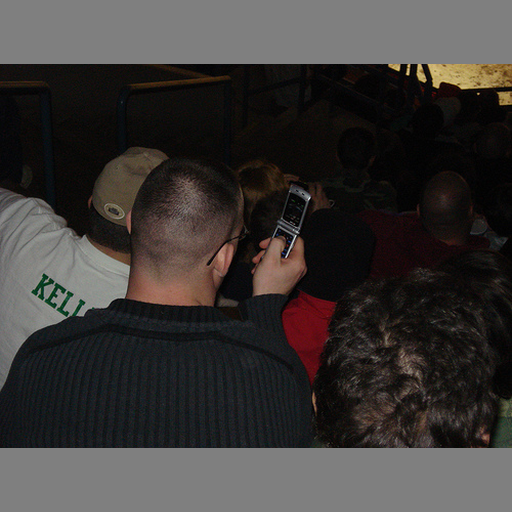

In [9]:

from PIL import Image, ImageOps
from io import BytesIO
import requests

# Reproduce Yosephine's preprocessing pipeline
def load_image(url):
    response = requests.get(url, timeout=60)
    response.raise_for_status()

    with Image.open(BytesIO(response.content)) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")

        return ImageOps.pad(
            img,
            (512, 512),
            method=Image.Resampling.LANCZOS,
            color=(127, 127, 127)
        )

# Download the same 8 images used for text embeddings
images = [
    load_image(url)
    for url in sample["download_url"]
]

# Prepare images for CLIP
image_inputs = processor(
    images=images,
    return_tensors="pt"
).to(device)

# Generate image embeddings
with torch.inference_mode():
    output = model.get_image_features(**image_inputs)

    features = (
        output if isinstance(output, torch.Tensor)
        else output.pooler_output
    )

    image_embeddings = F.normalize(features, p=2, dim=-1)

print("Images loaded:", len(images))
print("Embeddings shape:", image_embeddings.shape)

print("\nFirst caption:", captions[0])
display(images[0])


## 5. Image-Text Similarity Evaluation

In [11]:

# Compute cosine similarity between images and captions
similarity = image_embeddings @ text_embeddings.T

# Find the most similar caption for each image
best_matches = similarity.argmax(dim=1).cpu().tolist()

# Get similarity scores for correct pairs
correct_scores = similarity.diag().cpu().numpy()

results = pd.DataFrame({
    "Image": range(1, len(images) + 1),
    "Actual caption": captions,
    "Predicted caption": [captions[i] for i in best_matches],
    "Similarity": correct_scores.round(3),
    "Correct": [
        i == predicted
        for i, predicted in enumerate(best_matches)
    ]
})

print("Similarity matrix:", similarity.shape)
print(f"Top-1 accuracy: {results['Correct'].mean():.1%}")

display(results)


Similarity matrix: torch.Size([8, 8])
Top-1 accuracy: 87.5%


,Image,Actual caption,Predicted caption,Similarity,Correct
0,1,People gathered taking pictures with a cell ph...,A man in a gray shirt holds his phone as he si...,0.275,False
1,2,Two people standing on a tennis court playing ...,Two people standing on a tennis court playing ...,0.330,True
2,3,Many cars are parked along the sidewalk of a n...,Many cars are parked along the sidewalk of a n...,0.245,True
3,4,A man in a gray shirt holds his phone as he si...,A man in a gray shirt holds his phone as he si...,0.302,True
4,5,A large clock is on the wall where the paint i...,A large clock is on the wall where the paint i...,0.287,True
5,6,a female is talking on the phone and a laptop ...,a female is talking on the phone and a laptop ...,0.317,True
6,7,A cat and a dog on the floor in a room,A cat and a dog on the floor in a room,0.281,True
7,8,a couple of people on skis sit on top of a sno...,a couple of people on skis sit on top of a sno...,0.279,True


## 6. Validation on a Larger Sample

In [12]:

# Select 32 reproducible validation pairs
validation = (
    manifest[manifest["split"] == "validation"]
    .sample(n=32, random_state=42)
    .reset_index(drop=True)
)

batch_size = 8
text_vectors = []
image_vectors = []

for start in range(0, len(validation), batch_size):
    batch = validation.iloc[start:start + batch_size]

    batch_images = [
        load_image(url)
        for url in batch["download_url"]
    ]

    encoded = processor(
        text=batch["caption"].tolist(),
        images=batch_images,
        padding=True,
        truncation=True,
        max_length=77,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        t = model.get_text_features(
            input_ids=encoded["input_ids"],
            attention_mask=encoded["attention_mask"]
        )

        i = model.get_image_features(
            pixel_values=encoded["pixel_values"]
        )

        t = t if isinstance(t, torch.Tensor) else t.pooler_output
        i = i if isinstance(i, torch.Tensor) else i.pooler_output

        text_vectors.append(F.normalize(t, dim=-1).cpu())
        image_vectors.append(F.normalize(i, dim=-1).cpu())

# Combine all batches
text_matrix = torch.cat(text_vectors)
image_matrix = torch.cat(image_vectors)

# Evaluate image-to-text retrieval
scores = image_matrix @ text_matrix.T
predictions = scores.argmax(dim=1)

accuracy = (
    predictions == torch.arange(len(validation))
).float().mean().item()

print("Text embeddings:", text_matrix.shape)
print("Image embeddings:", image_matrix.shape)
print("Similarity matrix:", scores.shape)
print(f"Top-1 accuracy: {accuracy:.1%}")


Text embeddings: torch.Size([32, 512])
Image embeddings: torch.Size([32, 512])
Similarity matrix: torch.Size([32, 32])
Top-1 accuracy: 93.8%


## 7. Pipeline Verification and Reproducibility

In [13]:

from importlib.metadata import version
import platform

# Validate embedding dimensions
assert text_matrix.shape == (32, 512)
assert image_matrix.shape == (32, 512)
assert scores.shape == (32, 32)

# Check that embeddings contain valid numbers
assert torch.isfinite(text_matrix).all()
assert torch.isfinite(image_matrix).all()

# Verify L2 normalization
for matrix in [text_matrix, image_matrix]:
    norms = torch.linalg.vector_norm(matrix, dim=1)
    assert torch.allclose(
        norms, torch.ones_like(norms), atol=1e-4
    )

correct = int(
    (predictions == torch.arange(32)).sum().item()
)

print("Pipeline validation: PASSED")
print(f"Correct matches: {correct}/32")
print(f"Top-1 accuracy: {accuracy:.2%}")

print("\nEnvironment:")
print("Python:", platform.python_version())
print("GPU:", torch.cuda.get_device_name(0))

for package in [
    "torch", "transformers", "diffusers",
    "accelerate", "pandas", "pillow"
]:
    print(f"{package}: {version(package)}")


Pipeline validation: PASSED
Correct matches: 30/32
Top-1 accuracy: 93.75%

Environment:
Python: 3.13.15
GPU: Tesla T4
torch: 2.11.0+cu130
transformers: 5.20.1
diffusers: 0.41.0
accelerate: 1.15.0
pandas: 2.2.3
pillow: 11.3.0


## 8. Results and Conclusions

The CLIP image-text embedding pipeline was successfully implemented using the pretrained `openai/clip-vit-base-patch32` model.

The pipeline uses the curated COCO 2017 image-caption dataset prepared by the team, containing 1,000 image-caption pairs.

**Implementation:**
- Text captions were tokenized and encoded into 512-dimensional embeddings.
- Images were preprocessed and encoded into 512-dimensional embeddings.
- Both embedding types were L2-normalized.
- Cosine similarity was used to evaluate image-text alignment.

**Validation results:**

| Metric | Result |
|---|---|
| Initial test sample | 8 pairs |
| Initial Top-1 accuracy | 87.5% |
| Validation sample | 32 pairs |
| Correct matches | 30/32 |
| Validation Top-1 accuracy | 93.75% |
| Embedding dimensions | 512 |

**Conclusion:**

The pretrained CLIP model successfully generated image and text embeddings and demonstrated strong alignment on the selected validation sample. The pipeline operated end-to-end without errors.

These results are limited to small-sample retrieval evaluation and should not be interpreted as general model accuracy. No fine-tuning was performed.